In [1]:
import pandas as pd

In [2]:
df  = pd.read_excel(r"C:\Users\thesi\OneDrive\Desktop\E-Commerce-Data-Analysis\Data\online_retail_II.xlsx")
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


In [3]:
df.shape

(525461, 8)

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [6]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(6865)

In [8]:
(df["Quantity"] < 0).sum()

np.int64(12326)

In [9]:
(df["Price"] <= 0).sum()

np.int64(3690)

In [3]:
df_clean = df[df["Price"] > 0].copy()

In [4]:
df_clean.shape

(521771, 8)

In [5]:
df_clean.duplicated().sum()

np.int64(6859)

In [6]:
df_clean = df_clean.drop_duplicates().copy()

In [7]:
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    104180
Country             0
dtype: int64

In [8]:
df_clean["Customer ID"].nunique()

4381

In [9]:
df_clean["Customer ID"] = df_clean["Customer ID"].astype("Int64")

In [10]:
df_clean.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country                object
dtype: object

In [11]:
(df_clean["Quantity"]<0).sum()

np.int64(10181)

In [12]:
df_clean["TransactionType"] = df_clean["Quantity"].apply(
    lambda x: "Return" if x < 0 else "Sale"
)

In [14]:
df_clean[["Quantity", "TransactionType"]].head(10)

,Quantity,TransactionType
0,12,Sale
1,12,Sale
2,12,Sale
3,48,Sale
4,24,Sale
5,24,Sale
6,24,Sale
7,10,Sale
8,12,Sale
9,12,Sale


In [15]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

In [16]:
df_clean[["Revenue"]].head(10)

,Revenue
0,83.4
1,81.0
2,81.0
3,100.8
4,30.0
5,39.6
6,30.0
7,59.5
8,30.6
9,45.0


In [17]:
df_clean["Revenue"].sum()

np.float64(9642327.583999999)

In [18]:
df_clean["TransactionType"].value_counts()

TransactionType
Sale      504731
Return     10181
Name: count, dtype: int64

In [19]:
df_clean.groupby("TransactionType")["Revenue"].sum()

TransactionType
Return   -6.298087e+05
Sale      1.027214e+07
Name: Revenue, dtype: float64

In [21]:
return_rate = (
    (df_clean["TransactionType"] == "Return").sum()
    / len(df_clean)
) * 100

return_rate

np.float64(1.9772310608414643)

In [22]:
df_clean["InvoiceDate"].head()

0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
Name: InvoiceDate, dtype: datetime64[ns]

In [23]:
df_clean["Month"]= df_clean["InvoiceDate"].dt.to_period("M")

In [24]:
return_rate = (
    (df_clean["TransactionType"] == "Return").sum()
    / len(df_clean)
) * 100

return_rate

np.float64(1.9772310608414643)

In [26]:
df_clean[["InvoiceDate", "Month"]].head(10)

,InvoiceDate,Month
0,2009-12-01 07:45:00,2009-12
1,2009-12-01 07:45:00,2009-12
2,2009-12-01 07:45:00,2009-12
3,2009-12-01 07:45:00,2009-12
4,2009-12-01 07:45:00,2009-12
5,2009-12-01 07:45:00,2009-12
6,2009-12-01 07:45:00,2009-12
7,2009-12-01 07:45:00,2009-12
8,2009-12-01 07:46:00,2009-12
9,2009-12-01 07:46:00,2009-12


In [27]:
monthly_revenue = df_clean.groupby("Month")["Revenue"].sum()

monthly_revenue

Month
2009-12     796648.500
2010-01     622479.502
2010-02     531265.366
2010-03     763247.241
2010-04     641521.052
2010-05     613270.720
2010-06     677073.870
2010-07     617365.480
2010-08     654774.390
2010-09     851105.961
2010-10    1080611.480
2010-11    1416697.202
2010-12     376266.820
Freq: M, Name: Revenue, dtype: float64

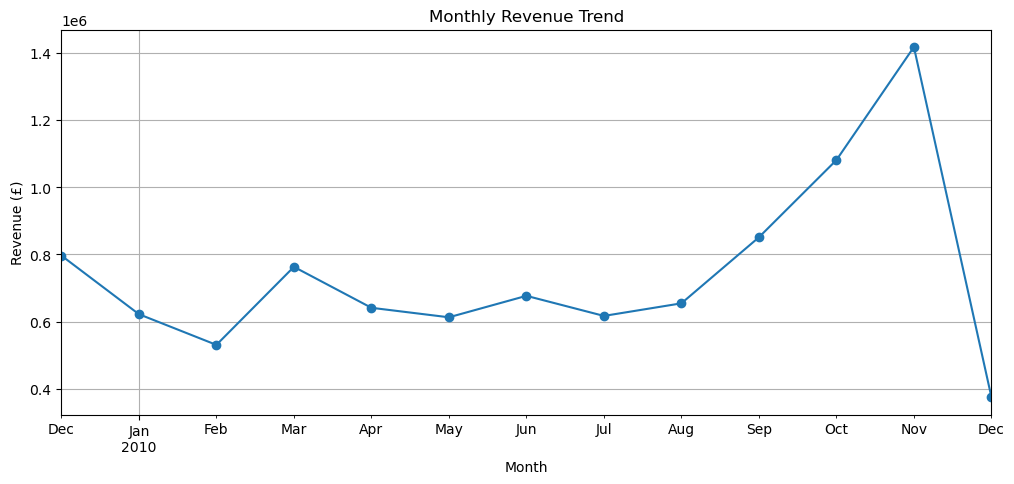

In [28]:
import matplotlib.pyplot as plt

monthly_revenue.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(True)
plt.show()

In [29]:
df_clean["InvoiceDate"].min(), df_clean["InvoiceDate"].max()

(Timestamp('2009-12-01 07:45:00'), Timestamp('2010-12-09 20:01:00'))

In [30]:
df_clean.groupby("Month")["InvoiceDate"].agg(["min", "max"])

,min,max
Month,,
2009-12,2009-12-01 07:45:00,2009-12-23 16:58:00
2010-01,2010-01-04 09:24:00,2010-01-31 16:02:00
2010-02,2010-02-01 08:13:00,2010-02-28 16:16:00
2010-03,2010-03-01 08:38:00,2010-03-31 17:31:00
2010-04,2010-04-01 07:49:00,2010-04-30 17:33:00
2010-05,2010-05-02 10:22:00,2010-05-30 15:58:00
2010-06,2010-06-01 09:02:00,2010-06-30 17:38:00
2010-07,2010-07-01 08:39:00,2010-07-30 17:08:00
2010-08,2010-08-01 10:04:00,2010-08-31 17:44:00


In [32]:
top_product = (
    df_clean.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values()
    .head()

)
top_product

StockCode     Description 
AMAZONFEE     AMAZON FEE     -39243.08
BANK CHARGES  Bank Charges   -26318.03
M             Manual         -14137.84
D             Discount        -7788.32
S             SAMPLES         -3016.41
Name: Revenue, dtype: float64

In [33]:
df_clean["StockCode"].value_counts().head(20)

StockCode
85123A    3468
22423     2200
85099B    2042
21212     1900
21232     1806
20725     1594
84879     1442
84991     1378
21754     1359
20914     1258
21931     1210
21080     1201
22139     1182
21977     1181
22383     1177
22138     1172
20727     1162
82494L    1155
21843     1142
21034     1139
Name: count, dtype: int64

In [39]:
df_clean[df_clean["StockCode"].str.len() < 5][
    ["StockCode", "Description"]
].drop_duplicates().head(30)

,StockCode,Description
89,POST,POSTAGE
735,D,Discount
2379,DOT,DOTCOM POSTAGE
2697,M,Manual
9292,C2,CARRIAGE
62299,PADS,PADS TO MATCH ALL CUSHIONS
96608,m,Manual
114061,S,SAMPLES


In [40]:
non_product_codes = [
    "POST",
    "D",
    "DOT",
    "M",
    "m",
    "C2",
    "S",
    "AMAZONFEE",
    "BANK CHARGES"
]

In [41]:
df_products = df_clean[
    ~df_clean["StockCode"].isin(non_product_codes)
].copy()

In [42]:
df_products.shape

(512120, 11)

In [43]:
top_products = (
    df_products.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

StockCode  Description                        
22423      REGENCY CAKESTAND 3 TIER               162885.71
85123A     WHITE HANGING HEART T-LIGHT HOLDER     155540.37
84879      ASSORTED COLOUR BIRD ORNAMENT           72251.32
22086      PAPER CHAIN KIT 50'S CHRISTMAS          57808.25
85099B     JUMBO BAG RED RETROSPOT                 54217.92
47566      PARTY BUNTING                           49626.92
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     47641.89
85099F     JUMBO BAG STRAWBERRY                    35823.39
15056N     EDWARDIAN PARASOL NATURAL               35748.00
21621      VINTAGE UNION JACK BUNTING              35717.71
Name: Revenue, dtype: float64

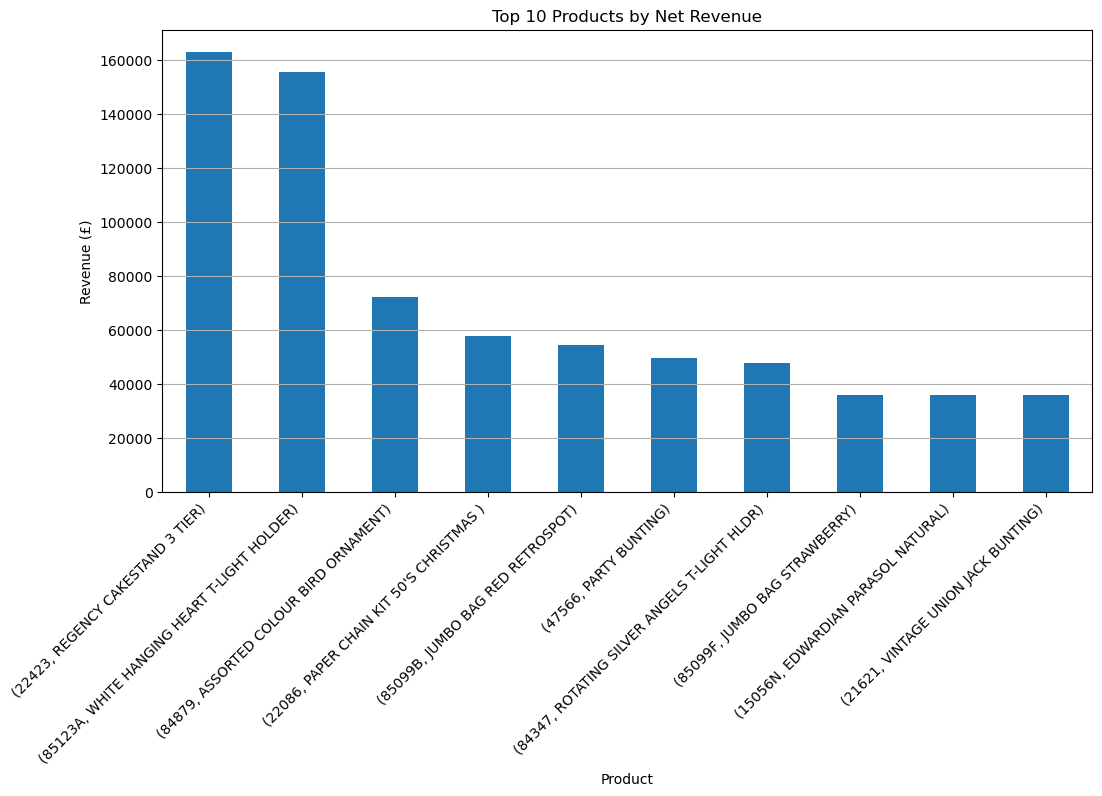

In [44]:
import matplotlib.pyplot as plt

top_products.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Products by Net Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.show()

In [48]:
top_countries = (
    df_products.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    
)

top_countries

Country
United Kingdom    8264122.013
EIRE               350426.140
Netherlands        262775.110
Germany            178777.371
France             117044.600
Sweden              49178.760
Denmark             46450.950
Switzerland         40658.410
Spain               34061.130
Australia           29976.800
Name: Revenue, dtype: float64

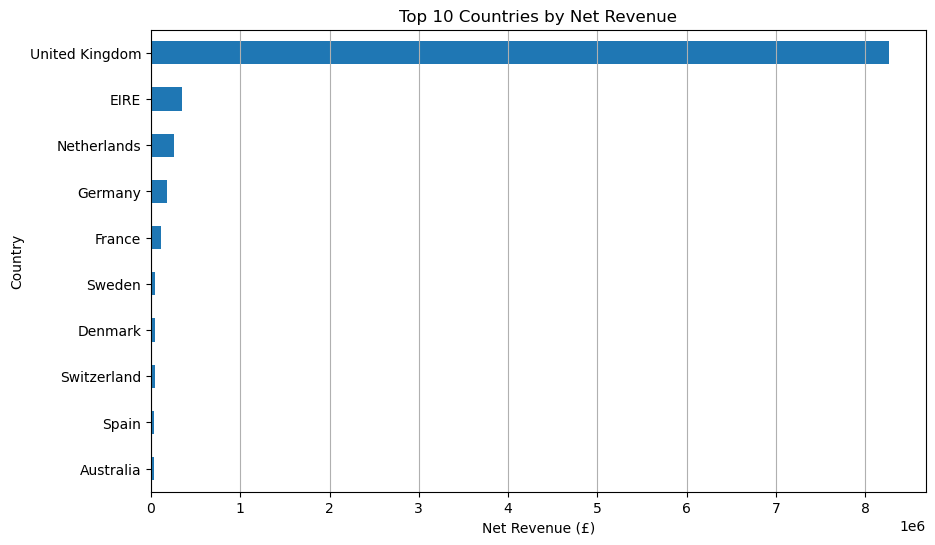

In [49]:
top_countries.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Countries by Net Revenue")
plt.xlabel("Net Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x")
plt.show()

In [50]:
transaction_counts = df_clean["TransactionType"].value_counts()

transaction_counts

TransactionType
Sale      504731
Return     10181
Name: count, dtype: int64

In [51]:
transaction_revenue = (
    df_clean.groupby("TransactionType")["Revenue"]
    .sum()
)

transaction_revenue

TransactionType
Return   -6.298087e+05
Sale      1.027214e+07
Name: Revenue, dtype: float64

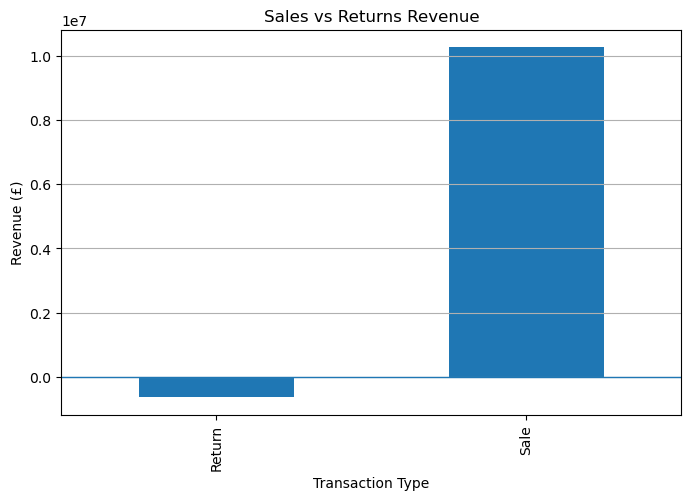

In [52]:
transaction_revenue.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales vs Returns Revenue")
plt.xlabel("Transaction Type")
plt.ylabel("Revenue (£)")
plt.axhline(0, linewidth=1)
plt.grid(axis="y")
plt.show()

In [53]:
top_customers = (
    df_clean.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer ID
18102    341776.73
14646    243853.05
14156    183163.55
14911    137710.76
13694    128172.42
17511     83760.60
15061     82162.74
16684     75610.17
13089     55801.73
16754     54558.18
Name: Revenue, dtype: float64

In [54]:
df_clean["Customer ID"].nunique()

4381

In [55]:
df_clean["Invoice"].nunique()

25543

In [56]:
aov = df_clean["Revenue"].sum() / df_clean["Invoice"].nunique()

aov

np.float64(377.49393508984843)

In [57]:
average_customer_revenue = (
    df_clean["Revenue"].sum()
    / df_clean["Customer ID"].nunique()
)

average_customer_revenue

np.float64(2200.942155672221)

In [58]:
average_orders_per_customer = (
    df_clean["Invoice"].nunique()
    / df_clean["Customer ID"].nunique()
)

average_orders_per_customer

5.830404017347638

In [59]:
orders_per_customer = (
    df_clean.groupby("Customer ID")["Invoice"]
    .nunique()
)

orders_per_customer.head()


Customer ID
12346    15
12347     2
12348     1
12349     4
12351     1
Name: Invoice, dtype: int64

In [60]:
repeat_customers = (orders_per_customer > 1).sum()

repeat_customers

np.int64(3116)

In [61]:
repeat_customer_rate = (
    repeat_customers
    / df_clean["Customer ID"].nunique()
) * 100

repeat_customer_rate

np.float64(71.12531385528418)

In [62]:
top_quantity_products = (
    df_products.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_quantity_products

StockCode  Description                       
85123A     WHITE HANGING HEART T-LIGHT HOLDER    57326
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     54443
17003      BROCADE RING PURSE                    47637
21212      PACK OF 72 RETRO SPOT CAKE CASES      46079
84879      ASSORTED COLOUR BIRD ORNAMENT         44797
84991      60 TEATIME FAIRY CAKE CASES           36172
21977      PACK OF 60 PINK PAISLEY CAKE CASES    31687
85099B     JUMBO BAG RED RETROSPOT               30247
22197      SMALL POPCORN HOLDER                  29449
21232      STRAWBERRY CERAMIC TRINKET BOX        26495
Name: Quantity, dtype: int64

In [63]:

df_clean.groupby("TransactionType")["Quantity"].sum()

TransactionType
Return    -213289
Sale      5812948
Name: Quantity, dtype: int64

In [64]:
unit_return_rate = (
    abs(df_clean[df_clean["TransactionType"] == "Return"]["Quantity"].sum())
    / df_clean[df_clean["TransactionType"] == "Sale"]["Quantity"].sum()
) * 100

unit_return_rate


np.float64(3.6692053670529994)

In [65]:
monthly_orders = (
    df_clean.groupby("Month")["Invoice"]
    .nunique()
)

monthly_orders

Month
2009-12    2083
2010-01    1405
2010-02    1441
2010-03    2088
2010-04    1766
2010-05    1907
2010-06    2002
2010-07    1873
2010-08    1698
2010-09    2210
2010-10    2777
2010-11    3323
2010-12     970
Freq: M, Name: Invoice, dtype: int64

In [66]:
monthly_aov = monthly_revenue / monthly_orders

monthly_aov

Month
2009-12    382.452472
2010-01    443.045909
2010-02    368.678255
2010-03    365.539866
2010-04    363.262204
2010-05    321.589261
2010-06    338.198736
2010-07    329.613177
2010-08    385.615071
2010-09    385.115819
2010-10    389.129089
2010-11    426.330786
2010-12    387.903938
Freq: M, dtype: float64

In [67]:
df_clean.to_csv("../data/ecommerce_cleaned.csv", index=False)